In [19]:
import pandas as pd
import pandapower as pp
from pandapower.converter.matpower import from_mpc
import pypsa
import matplotlib.pyplot as plt
import numpy as np
import os
from glob import glob
from pathlib import Path
import cartopy.crs as ccrs

In [2]:
from pandapower.converter.matpower.from_mpc import _m2ppc
from pandapower.converter.pypower import from_ppc

In [24]:
from zipfile import ZipFile
import requests
import json
import io
import us
import geopandas as gpd

state = 'wisconsin'
fips = us.states.lookup(state).fips
year = 2025
fname = f"tl_{year}_{fips}_tract"
tract_url = f"https://www2.census.gov/geo/tiger/TIGER{year}/TRACT/{fname}.zip"
county_url = 'https://www2.census.gov/geo/tiger/GENZ2018/shp/cb_2018_us_county_5m.zip'

# gdf = gpd.read_file('cb_2018_us_county_5m.shp')
gdf = gpd.read_file(f'{fname}.shp')
gdf.head()

,STATEFP,COUNTYFP,TRACTCE,GEOID,GEOIDFQ,NAME,NAMELSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,55,019,950800,55019950800,1400000US55019950800,9508,Census Tract 9508,G5020,S,794216668,8168460,+44.5759654,-090.7481080,"POLYGON ((-90.92288 44.50992, -90.92286 44.510..."
1,55,019,950500,55019950500,1400000US55019950500,9505,Census Tract 9505,G5020,S,411510103,886442,+44.7920881,-090.4318739,"POLYGON ((-90.55764 44.85698, -90.55763 44.859..."
2,55,019,950100,55019950100,1400000US55019950100,9501,Census Tract 9501,G5020,S,105161812,384034,+44.9773747,-090.3669679,"POLYGON ((-90.43417 44.96585, -90.43415 44.966..."
3,55,019,950700,55019950700,1400000US55019950700,9507,Census Tract 9507,G5020,S,104152998,1410731,+44.6211439,-090.6045574,"POLYGON ((-90.65958 44.64192, -90.65957 44.642..."
4,55,019,950400,55019950400,1400000US55019950400,9504,Census Tract 9504,G5020,S,564233017,5519077,+44.8087893,-090.7306337,"POLYGON ((-90.92251 44.90083, -90.92032 44.900..."


In [3]:
case_data_path = Path("../case_data/Wisconsin_1664.m")

In [4]:
ppc = _m2ppc(case_data_path)

In [5]:
gc = ppc["gencost"]
assert np.all(gc[:, 3] == 4) and np.allclose(gc[:, 4], 0)   # uniform NCOST=4, zero cubic

ppc["gencost"] = np.c_[gc[:, :4], gc[:, 5:8]]   # keep c2, c1, c0
ppc["gencost"][:, 3] = 3

net = from_ppc(ppc, f_hz=60) 

c:\Users\SDotson\miniforge3\envs\Midwest24k\Lib\site-packages\pandapower\converter\pypower\from_ppc.py:330: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  branch_lookup.loc[is_trafo, "element"] = idx_trafo


In [6]:
net = from_ppc(ppc, f_hz=60)

c:\Users\SDotson\miniforge3\envs\Midwest24k\Lib\site-packages\pandapower\converter\pypower\from_ppc.py:330: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  branch_lookup.loc[is_trafo, "element"] = idx_trafo


In [7]:
n = pypsa.Network()
n.import_from_pypower_ppc(ppc)
n.generators["marginal_cost"] = ppc["gencost"][:, 5]
n.generators["marginal_cost_quadratic"] = ppc["gencost"][:, 4]

c:\Users\SDotson\miniforge3\envs\Midwest24k\Lib\site-packages\pypsa\network\io.py:2082: FutureWarning: pandas infers the `str` dtype for string data since its version 3.0. PyPSA still converts it back to numpy object dtype on import, but will keep it from PyPSA 2.0 on. Set `pypsa.options.api.legacy_string_dtype` explicitly to suppress this warning.
  new_static = _coerce_string_dtypes(new_static)


In [8]:
n.sanitize()

INFO:pypsa.consistency:Sanitizing network...
INFO:pypsa.components._types.carriers:Adding 1 missing carriers: ['AC']
INFO:pypsa.components._types.carriers:Assigned colors to 1 carriers using 'tab10' palette.
INFO:pypsa.consistency:Network sanitization complete.


In [12]:
# The original values come from an AC power flow model -- not PyPSA.
# Reset the values to NaN
n.generators.p_set = np.nan

In [26]:
n.lines.s_nom_extendable = True

In [28]:
n.lines.s_nom_extendable

name
L0       True
L1       True
L2       True
L3       True
L4       True
         ... 
L1897    True
L1898    True
L1899    True
L1900    True
L1901    True
Name: s_nom_extendable, Length: 1902, dtype: bool

In [13]:
n.optimize(solver_name='highs')

C:\Users\SDotson\AppData\Local\Temp\ipykernel_44960\2578778796.py:1: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  n.optimize(solver_name='highs')
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.37s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 2541 primals, 7545 duals
Objective: 1.32e+05
Solver: highs
Runtime: 0.36s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Line-fix-s-lower, Line-fix-s-upper, Transformer-fix-s-lower, Transformer-fix-s-upper, Kirchhoff-Voltage-Law were not assigned to the network.


('ok', 'optimal')

In [14]:
n.lpf()

INFO:pypsa.network.power_flow:Performing linear load-flow on AC sub-network <pypsa.networks.SubNetwork object at 0x000002DFDD2D3B10> for snapshot(s) Index(['now'], dtype='object', name='snapshot')


In [28]:
n

PyPSA Network 'Unnamed Network'
-------------------------------
Components:
 - Bus: 1664
 - Carrier: 1
 - Generator: 79
 - Line: 1902
 - Load: 1393
 - ShuntImpedance: 30
 - SubNetwork: 1
 - Transformer: 560
Snapshots: 1

In [ ]:
n.generators

,bus,control,type,p_nom,p_nom_mod,p_nom_extendable,p_nom_min,p_nom_max,p_nom_set,p_min_pu,...,Pc2,Qc1min,Qc1max,Qc2min,Qc2max,ramp_agc,ramp_10,ramp_30,ramp_q,apf
name,,,,,,,,,,,,,,,,,,,,,
G0,0,Slack,,1286.0,0.0,False,0.0,inf,NaN,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
G1,1,PV,,1240.0,0.0,False,0.0,inf,NaN,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
G2,2,PV,,1233.2,0.0,False,0.0,inf,NaN,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
G3,3,PV,,604.4,0.0,False,0.0,inf,NaN,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
G4,3,PV,,604.4,0.0,False,0.0,inf,NaN,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
G74,73,PV,,21.6,0.0,False,0.0,inf,NaN,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
G75,74,PV,,20.8,0.0,False,0.0,inf,NaN,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
G76,75,PV,,20.0,0.0,False,0.0,inf,NaN,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


ValueError: Colors not defined for all elements in the second MultiIndex 

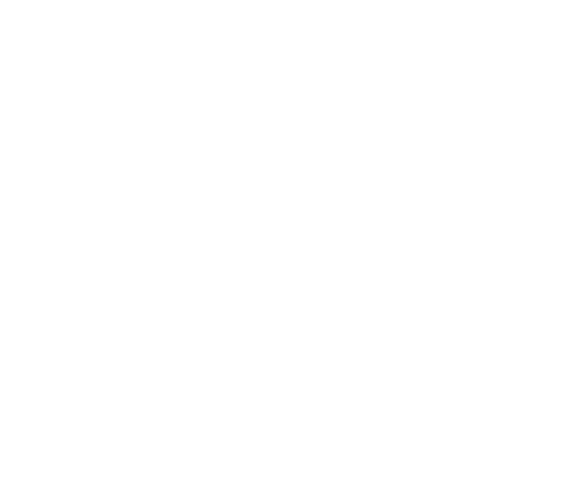

In [25]:
fig, ax = plt.subplots(figsize=(8,6), subplot_kw={'projection':ccrs.Mercator()})
n.plot(ax=ax, 
      
       bus_size=n.generators.groupby(['bus', 'carrier']).p_nom.sum()/(n.generators.p_nom.sum()*2),
      #  bus_split_circle=True,
       # bus_size=0.002,
       line_alpha=1,
       line_color='tab:blue',
       line_width=n.lines.s_nom /n.lines.s_nom.mean(),
       branch_components = ['Line', 'Transformer']
       # branch_components = ['Line']
       )
gdf.to_crs(ax.projection.proj4_init).plot(ax=ax, fc='None',ec='k',lw=0.1,zorder=0)
plt.show()